# AI4I 2020 Predictive Maintenance - Random Forest

## CIS 480 Capstone | Machine failure prediction and operating-condition importance

### Uses the same src/modeling/model_utils.py, cleaned data, stratified split, and evaluation metrics as logistic_regression.ipynb.

## 1. Imports and project paths

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_validate, RandomizedSearchCV
from sklearn.metrics import (classification_report, ConfusionMatrixDisplay,
                             RocCurveDisplay, PrecisionRecallDisplay)
from sklearn.inspection import permutation_importance


def find_root():
    for candidate in (Path.cwd(), *Path.cwd().parents):
        if (candidate / 'src' / 'modeling' / 'model_utils.py').exists():
            return candidate
    raise FileNotFoundError('Open the cis480_capstone project folder in VS Code.')

PROJECT_ROOT = find_root()
sys.path.insert(0, str(PROJECT_ROOT / 'src' / 'modeling'))
from model_utils import (RANDOM_STATE, PREDICTORS, TARGET, CV_SCORING,
                         load_clean_data, split_data, make_pipeline, make_cv,
                         evaluate_classifier)
FIGURES_DIR = PROJECT_ROOT / 'reports' / 'figures'
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

## 2. Load and validate cleaned data

The initial notebook removed 27 inconsistent failure-label observations. This notebook uses that exported cleaned dataset instead of repeating cleaning.

In [2]:
df = load_clean_data(PROJECT_ROOT)
print(f'Rows: {len(df):,} | Columns: {df.shape[1]}')
display(df[PREDICTORS + [TARGET]].head())
display(pd.DataFrame({'Count': df[TARGET].value_counts().sort_index(),
                      'Percentage': df[TARGET].value_counts(normalize=True).sort_index().mul(100).round(2)}))

Rows: 9,973 | Columns: 14


,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure
0,M,298.1,308.6,1551,42.8,0,0
1,L,298.2,308.7,1408,46.3,3,0
2,L,298.1,308.5,1498,49.4,5,0
3,L,298.2,308.6,1433,39.5,7,0
4,L,298.2,308.7,1408,40.0,9,0


,Count,Percentage
Machine failure,,
0,9643,96.69
1,330,3.31


## 3. Stratified training/test split

Use the same 80/20 split and random_state=42 as the initial notebook so later models can be compared fairly. Do not use the test set to select hyperparameters or thresholds.

In [3]:
X_train, X_test, y_train, y_test = split_data(df)
print(f'Train: {len(X_train):,} | Failure rate: {y_train.mean():.2%}')
print(f'Test:  {len(X_test):,} | Failure rate: {y_test.mean():.2%}')

Train: 7,978 | Failure rate: 3.31%
Test:  1,995 | Failure rate: 3.31%


## 4. Baseline Random Forest

Random Forest captures nonlinear effects and interactions. Use class_weight="balanced" to give rare failures more weight, and min_samples_leaf=2 as a modest regularization setting. Type is one-hot encoded inside the shared pipeline.

In [4]:
rf_model = make_pipeline(
    RandomForestClassifier(n_estimators=300, min_samples_leaf=2,
                           class_weight='balanced', random_state=RANDOM_STATE,
                           n_jobs=-1),
    scale_numeric=False
)
rf_model.fit(X_train, y_train)
print('Random Forest fitted.')

Random Forest fitted.


## 5. Five-fold stratified cross-validation (training data only)

In [5]:
cv_results = cross_validate(rf_model, X_train, y_train, cv=make_cv(),
                            scoring=CV_SCORING, n_jobs=-1)
cv_summary = pd.DataFrame({
    metric: {'Mean': cv_results[f'test_{metric}'].mean(),
             'Std': cv_results[f'test_{metric}'].std()}
    for metric in CV_SCORING
}).T
cv_summary.index.name = 'Metric'
display(cv_summary.round(4))

,Mean,Std
Metric,,
precision,0.5903,0.0273
recall,0.7649,0.0324
f1,0.6657,0.0217
roc_auc,0.9828,0.0010
average_precision,0.7562,0.0460


## 6. Held-out test evaluation

The default threshold is 0.50, matching the Logistic Regression baseline.

In [6]:
rf_metrics, y_pred, y_prob = evaluate_classifier(rf_model, X_test, y_test)
display(rf_metrics.round(4))
print(classification_report(y_test, y_pred, target_names=['No Failure', 'Failure'], zero_division=0))

,Metric,Score
0,Accuracy,0.9789
1,Precision,0.6500
2,Recall,0.7879
3,F1 Score,0.7123
4,ROC-AUC,0.9725
5,Average Precision (PR-AUC),0.8030


              precision    recall  f1-score   support

  No Failure       0.99      0.99      0.99      1929
     Failure       0.65      0.79      0.71        66

    accuracy                           0.98      1995
   macro avg       0.82      0.89      0.85      1995
weighted avg       0.98      0.98      0.98      1995



## 7. Metrics, Confusion matrix, ROC curve, and precision-recall curve

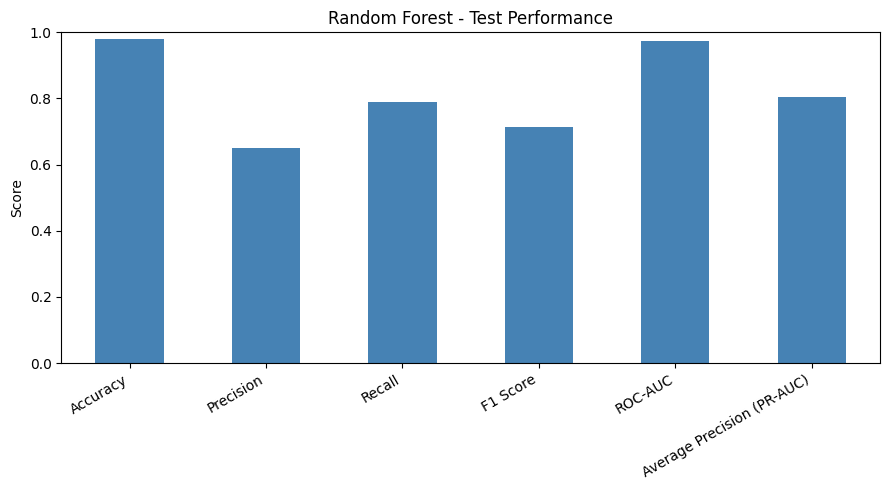

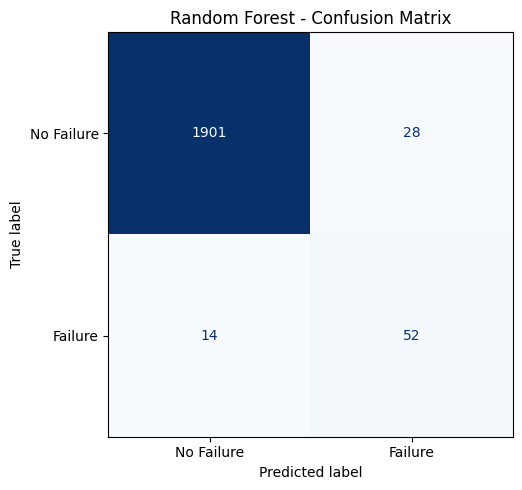

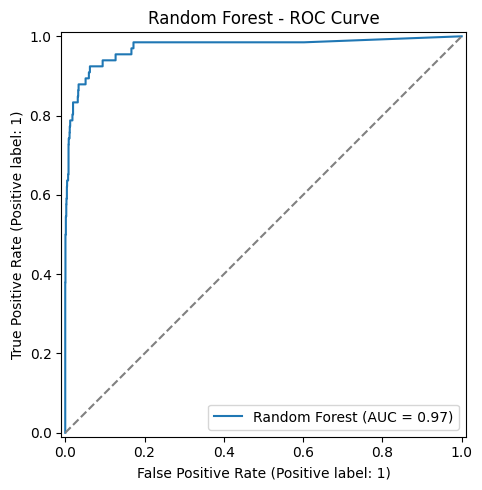

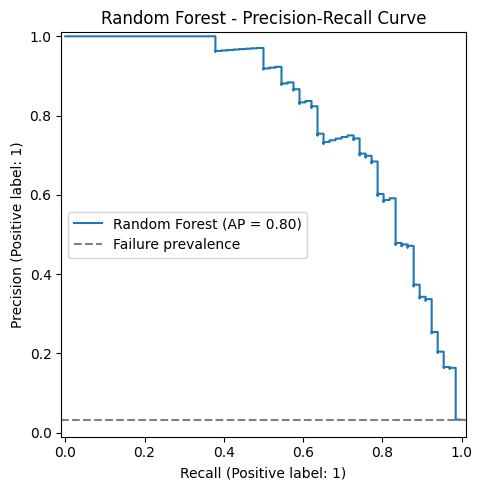

In [9]:
ax = rf_metrics.plot.bar(x="Metric", y="Score", legend=False, figsize=(9,5), color="steelblue")
ax.set(title="Random Forest - Test Performance", xlabel="", ylabel="Score", ylim=(0,1))
plt.xticks(rotation=30, ha="right"); plt.tight_layout()
ax.figure.savefig(FIGURES_DIR / "random_forest_metrics.png", dpi=160)
plt.show()


fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=['No Failure', 'Failure'],
                                        cmap='Blues', ax=ax, colorbar=False)
ax.set_title('Random Forest - Confusion Matrix')
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'random_forest_confusion_matrix.png', dpi=160)
plt.show()

fig, ax = plt.subplots(figsize=(6, 5))
RocCurveDisplay.from_predictions(y_test, y_prob, ax=ax, name='Random Forest')
ax.plot([0, 1], [0, 1], '--', color='gray')
ax.set_title('Random Forest - ROC Curve')
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'random_forest_roc.png', dpi=160)
plt.show()

fig, ax = plt.subplots(figsize=(6, 5))
PrecisionRecallDisplay.from_predictions(y_test, y_prob, ax=ax, name='Random Forest')
ax.axhline(y_test.mean(), linestyle='--', color='gray', label='Failure prevalence')
ax.legend()
ax.set_title('Random Forest - Precision-Recall Curve')
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'random_forest_precision_recall.png', dpi=160)
plt.show()

## 8. Permutation importance: which operating conditions matter?

Shuffle each original input column and measure the decrease in average precision. This keeps Type together as a single feature.

,Feature,Mean AP decrease,Std
3,Rotational speed [rpm],0.4496,0.0324
4,Torque [Nm],0.4386,0.0410
1,Air temperature [K],0.3175,0.0393
5,Tool wear [min],0.2597,0.0252
2,Process temperature [K],0.1820,0.0517
0,Type,0.0448,0.0117


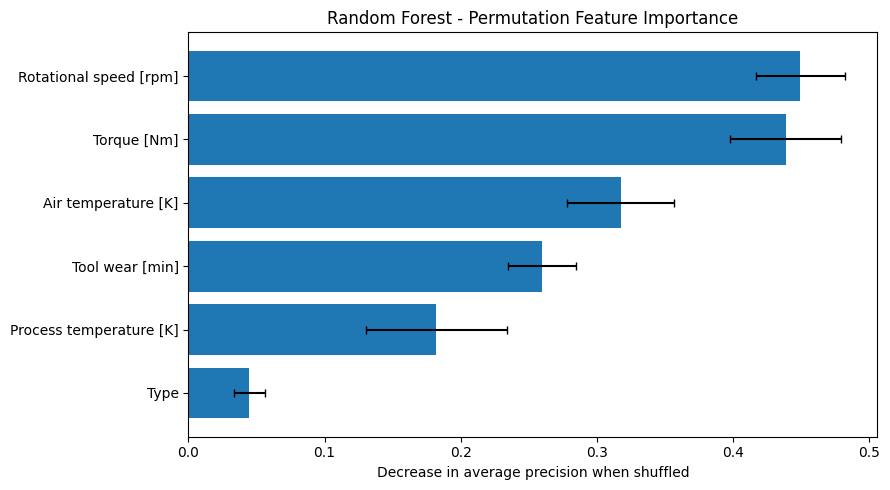

In [8]:
importance = permutation_importance(
    rf_model, X_test, y_test, scoring='average_precision',
    n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1
)
importance_df = pd.DataFrame({
    'Feature': X_test.columns,
    'Mean AP decrease': importance.importances_mean,
    'Std': importance.importances_std
}).sort_values('Mean AP decrease', ascending=False)
display(importance_df.round(4))

plot_df = importance_df.sort_values('Mean AP decrease')
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(plot_df['Feature'], plot_df['Mean AP decrease'], xerr=plot_df['Std'], capsize=3)
ax.set_xlabel('Decrease in average precision when shuffled')
ax.set_title('Random Forest - Permutation Feature Importance')
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'random_forest_permutation_importance.png', dpi=160)
plt.show()